# Notebook 03 — Problem Definition and Fair Splitting





In [1]:
import sys
import os

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.append(repo_root)
if os.getcwd() not in sys.path:
    sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import src.data_loader as dl
import src.splitting as splitting

fig_dir = "results/figures" if os.path.exists("results/figures") else "../results/figures"
manifest_dir = "data/processed" if os.path.exists("data/processed") else "../data/processed"
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(manifest_dir, exist_ok=True)


## 2. Spatial Autocorrelation & The Flaw of Random Row Splitting


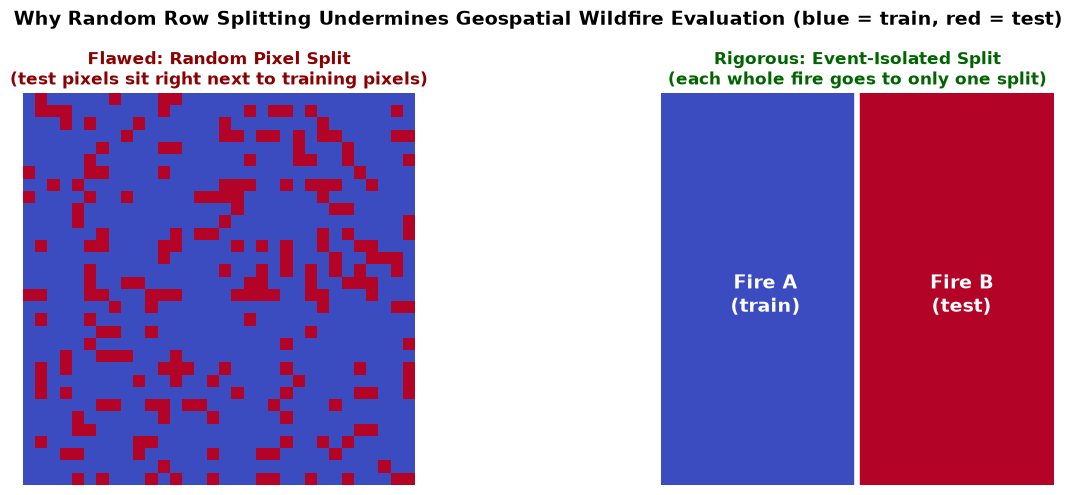

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

grid_size = 32
np.random.seed(42)

random_mask = np.random.choice([0, 1], size=(grid_size, grid_size), p=[0.8, 0.2])
axes[0].imshow(random_mask, cmap="coolwarm", vmin=0, vmax=1, interpolation="none")
axes[0].set_title("Flawed: Random Pixel Split\n(test pixels sit right next to training pixels)", fontsize=12, fontweight="bold", color="darkred")
axes[0].axis("off")

event_mask = np.zeros((grid_size, grid_size))
event_mask[:, grid_size // 2:] = 1
axes[1].imshow(event_mask, cmap="coolwarm", vmin=0, vmax=1, interpolation="none")
axes[1].axvline(grid_size / 2 - 0.5, color="white", lw=4)
axes[1].text(grid_size / 4, grid_size / 2, "Fire A\n(train)", ha="center", va="center", color="white", fontsize=14, fontweight="bold")
axes[1].text(3 * grid_size / 4, grid_size / 2, "Fire B\n(test)", ha="center", va="center", color="white", fontsize=14, fontweight="bold")
axes[1].set_title("Rigorous: Event-Isolated Split\n(each whole fire goes to only one split)", fontsize=12, fontweight="bold", color="darkgreen")
axes[1].axis("off")

plt.suptitle("Why Random Row Splitting Undermines Geospatial Wildfire Evaluation (blue = train, red = test)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(fig_dir, "spatial_leakage_concept.png"), dpi=200)
plt.show()

## 3. Official Disjoint Event Splitting Protocol
We strictly adopt the spatial and temporal event partitions established by Huot et al. (2022).
Every TFRecord shard encapsulates independent wildfire events across geographic regions and years:
- **Training Set**: 15 distinct shards (`next_day_wildfire_spread_train_00` to `_14`).
- **Validation Set**: 2 held-out shards (`next_day_wildfire_spread_eval_00` and `_01`).
- **Test Set**: 2 held-out shards (`next_day_wildfire_spread_test_00` and `_01`).


In [3]:
raw_dir = "data/raw/archive" if os.path.exists("data/raw/archive") else "../data/raw/archive"
manifest_path = os.path.join(manifest_dir, "split_manifest.csv")

manifest_df = splitting.create_split_manifest(raw_dir=raw_dir, output_path=manifest_path)
print(f"Generated official Split Manifest at: {manifest_path}")
display(manifest_df.head(10))


Generated official Split Manifest at: ../data/processed/split_manifest.csv


,shard_filename,relative_path,assigned_split,file_size_mb,spatial_temporal_isolation,leakage_risk
0,next_day_wildfire_spread_train_00.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
1,next_day_wildfire_spread_train_01.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
2,next_day_wildfire_spread_train_02.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
3,next_day_wildfire_spread_train_03.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
4,next_day_wildfire_spread_train_04.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
5,next_day_wildfire_spread_train_05.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
6,next_day_wildfire_spread_train_06.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
7,next_day_wildfire_spread_train_07.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
8,next_day_wildfire_spread_train_08.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)
9,next_day_wildfire_spread_train_09.tfrecord,../data/raw/archive/next_day_wildfire_spread_t...,train,203.43,Verified,None (Disjoint Event Partition)


## 4. Extracting Leakage-Free Tabular Partitions



In [4]:
interim_dir = "data/interim" if os.path.exists("data/interim") else "../data/interim"

train_df = dl.extract_split_tabular("train", max_patches=30, sample_negatives_ratio=10.0)
eval_df = dl.extract_split_tabular("eval", max_patches=10, sample_negatives_ratio=10.0)
test_df = dl.extract_split_tabular("test", max_patches=10, sample_negatives_ratio=10.0)

train_df.to_csv(os.path.join(interim_dir, "train_sample.csv"), index=False)
eval_df.to_csv(os.path.join(interim_dir, "eval_sample.csv"), index=False)
test_df.to_csv(os.path.join(interim_dir, "test_sample.csv"), index=False)

split_counts = pd.DataFrame([
    {"Split": "Train", "Total Pixels": len(train_df), "Active Burn Pixels": int(train_df["FireMask"].sum()), "Prevalence (%)": round(float(train_df["FireMask"].mean()) * 100, 2)},
    {"Split": "Validation", "Total Pixels": len(eval_df), "Active Burn Pixels": int(eval_df["FireMask"].sum()), "Prevalence (%)": round(float(eval_df["FireMask"].mean()) * 100, 2)},
    {"Split": "Test", "Total Pixels": len(test_df), "Active Burn Pixels": int(test_df["FireMask"].sum()), "Prevalence (%)": round(float(test_df["FireMask"].mean()) * 100, 2)},
])
display(split_counts)

disjoint_check = splitting.verify_disjoint_splits(train_df, eval_df, test_df)
print("\n--- Leakage Verification Checklist ---")
for check_name, status in disjoint_check.items():
    label = "PASS" if status else "FAIL"
    print(f"  [{label}] {check_name}: {status}")

I0000 00:00:1793218133.706420  268321 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


,Split,Total Pixels,Active Burn Pixels,Prevalence (%)
0,Train,77244,62,0.08
1,Validation,26125,39,0.15
2,Test,14429,157,1.09



--- Leakage Verification Checklist ---
  [PASS] train_eval_disjoint: True
  [PASS] train_test_disjoint: True
  [PASS] eval_test_disjoint: True
  [PASS] zero_target_in_features: True


In [5]:
metrics_dir = "results/metrics" if os.path.exists("results/metrics") else "../results/metrics"
os.makedirs(metrics_dir, exist_ok=True)

row_counts = []
for split, n_maps, df in [("train", 30, train_df), ("eval", 10, eval_df), ("test", 10, test_df)]:
    squares = 0
    unobserved = 0
    empty_maps = 0
    fire_maps = 0
    fire_rows = 0
    sampled_no_fire_rows = 0
    no_fire_maps = 0
    no_fire_rows = 0
    for patch in dl.iter_records(dl.get_tfrecord_paths(split), max_records=n_maps):
        squares += 4096
        valid = (patch["FireMask"] >= 0) & (patch["PrevFireMask"] >= 0)
        unobserved += int((~valid).sum())
        n_valid = int(valid.sum())
        n_fire = int(((patch["FireMask"] == 1) & valid).sum())
        if n_valid == 0:
            empty_maps += 1
        elif n_fire > 0:
            fire_maps += 1
            fire_rows += n_fire
            sampled_no_fire_rows += min(n_valid - n_fire, int(max(n_fire * 10, 20)))
        else:
            no_fire_maps += 1
            no_fire_rows += n_valid
    rows_used = fire_rows + sampled_no_fire_rows + no_fire_rows
    assert rows_used == len(df)
    burning_today = df["PrevFireMask"] == 1
    fire_tomorrow = df["FireMask"] == 1
    row_counts.append({
        "Split": split,
        "Maps read": n_maps,
        "Squares": squares,
        "Unobserved removed": unobserved,
        "Empty maps": empty_maps,
        "Maps with fire": fire_maps,
        "Fire rows": fire_rows,
        "Sampled no-fire rows": sampled_no_fire_rows,
        "Maps without fire": no_fire_maps,
        "Rows from maps without fire": no_fire_rows,
        "Rows used": rows_used,
        "Fire share (%)": round(fire_rows / rows_used * 100, 2),
        "Fires also burning today": int((fire_tomorrow & burning_today).sum()),
        "Burning today but not tomorrow": int((~fire_tomorrow & burning_today).sum())
    })

row_counts_df = pd.DataFrame(row_counts)
row_counts_df.to_csv(os.path.join(metrics_dir, "row_counts.csv"), index=False)
display(row_counts_df.T)


,0,1,2
Split,train,eval,test
Maps read,30,10,10
Squares,122880,40960,40960
Unobserved removed,5729,11168,8093
Empty maps,0,1,0
Maps with fire,10,1,5
Fire rows,62,39,157
Sampled no-fire rows,620,390,1590
Maps without fire,20,8,5
Rows from maps without fire,76562,25696,12682
